# Stage 3 — Train + explain

**Pipeline stage 3 of 5**: patient-level split → phase segmentation → **train + explain** →
candidate discovery → confirm & report.

Trains the CRNN classifier and, more importantly for this project, generates a Grad-CAM
explanation for **every development-set recording** — these, combined with Stage 2's phase
boundaries, are what Stage 4 turns into candidate acoustic markers.

## Why k-fold, not one model trained on everything

If we trained one model on the whole development set and then asked it to explain those same
recordings, the explanations would partly reflect what the model *memorized*, not what it
*generalises* on — exactly the kind of self-graded-homework problem Stage 5's locked
confirmation cohort exists to avoid, just one level earlier. So instead:

- The development set is split into `N_FOLDS` patient-grouped folds.
- For each fold *k*: train a model on everything **except** fold *k*'s patients, then use that
  model to explain **only** fold *k*'s recordings.
- Repeat for every fold, so every development recording ends up explained by a model that
  never saw its patient during training — a genuine **out-of-fold** explanation.

This also means Stage 3 naturally produces `N_FOLDS` trained model checkpoints (needed later
for Stage 4's occlusion testing) and a properly out-of-fold estimate of classifier performance
— a more honest accuracy number than a single train/val/test split would give.

## Why Grad-CAM always targets the MI class

Every recording's heatmap is computed against the **MI class score**, never "whichever class
was predicted." This is deliberate: it means a high heatmap value always means the same thing
— "evidence toward MI" — on every recording, whether it's truly MI or truly Normal. That's what
makes it valid to compare heatmap energy between the two classes in Stage 4; if some
recordings' heatmaps showed "evidence for MI" and others showed "evidence for Normal", the
numbers wouldn't be comparable at all.

All model/training/explanation code lives in `pipeline_common/` (`models.py`, `training.py`,
`features.py`, `explain.py`) — shared, not copy-pasted, so Stage 5's later confirmation-set
inference uses identical code, not a re-implementation that could quietly drift.

**Runtime note**: this is the most expensive stage in the pipeline — `N_FOLDS` full training
runs plus a Grad-CAM backward pass per recording. Expect it to take a while on your full
dataset; each fold's progress prints as it goes.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# ---- Setup ----------------------------------------------------------------
import sys
import json
import datetime
import pathlib

import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score

package_path = "/content/drive/MyDrive/Research 2026/mi_marker_pipeline"
if package_path not in sys.path:
    sys.path.insert(0, package_path)

from pipeline_common import config
from pipeline_common.audio import load_and_resample, pad_or_trim
from pipeline_common.features import calculate_features, n_freq_bins, PCGDataset
from pipeline_common.models import make_model
from pipeline_common.training import compute_class_weights, train_model
from pipeline_common.explain import GradCAM

import random
random.seed(config.SEED); np.random.seed(config.SEED); torch.manual_seed(config.SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

PREV_STAGE_DIR = config.ARTIFACTS_DIR / "01_split"
STAGE_DIR = config.ARTIFACTS_DIR / "03_train_explain"
MODELS_DIR = STAGE_DIR / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)

N_FREQ_BINS = n_freq_bins()
print("Saving this stage's output to:", STAGE_DIR)

Using device: cuda
Saving this stage's output to: /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/03_train_explain


## 1. Load development-set recordings, set up patient-grouped k-fold

In [ ]:
metadata = pd.read_csv(PREV_STAGE_DIR / "metadata_with_split.csv")
dev_metadata = metadata[metadata["split"] == "development"].reset_index(drop=True)

patient_df = (
    dev_metadata.groupby("patient_id")
    .agg(label=("label", "first"), class_name=("class_name", "first"))
    .reset_index()
)
class_counts = patient_df["label"].value_counts()
print(f"{len(dev_metadata)} development recordings, {len(patient_df)} patients")
print("Patients per class:", dict(class_counts))

if len(class_counts) < 2 or class_counts.min() < config.MIN_PATIENTS_PER_CLASS_FOR_KFOLD:
    raise SystemExit(
        f"Only {dict(class_counts)} patient(s) per class -- need at least "
        f"{config.MIN_PATIENTS_PER_CLASS_FOR_KFOLD} per class for {config.N_FOLDS}-fold CV. "
        f"Add more patients, or lower config.N_FOLDS, and re-run."
    )

skf = StratifiedKFold(n_splits=config.N_FOLDS, shuffle=True, random_state=config.SEED)
fold_splits = list(skf.split(patient_df, patient_df["label"]))
print(f"\n{config.N_FOLDS}-fold split ready.")

2688 development recordings, 112 patients
Patients per class: {1: np.int64(56), 0: np.int64(56)}

5-fold split ready.


## 2. Train one model per fold, explain that fold's held-out recordings

For each fold: train on every other fold's patients (with a further patient-grouped inner
train/val split for early stopping), save the checkpoint, then run Grad-CAM + prediction on
this fold's held-out recordings only.

In [ ]:
all_pred_rows = []
all_cams = []
fold_assignment_rows = []

for fold_idx, (train_val_idx, held_out_idx) in enumerate(fold_splits):
    held_out_patients = patient_df.iloc[held_out_idx]
    train_val_patients = patient_df.iloc[train_val_idx]

    for _, r in held_out_patients.iterrows():
        fold_assignment_rows.append({"patient_id": r["patient_id"], "class_name": r["class_name"],
                                     "fold_index": fold_idx})

    inner_train_patients, inner_val_patients = train_test_split(
        train_val_patients, test_size=config.INNER_VAL_FRACTION,
        stratify=train_val_patients["label"], random_state=config.SEED,
    )

    inner_train_df = dev_metadata[dev_metadata["patient_id"].isin(inner_train_patients["patient_id"])]
    inner_val_df = dev_metadata[dev_metadata["patient_id"].isin(inner_val_patients["patient_id"])]
    held_out_df = dev_metadata[dev_metadata["patient_id"].isin(held_out_patients["patient_id"])].reset_index(drop=True)

    print(f"\n=== Fold {fold_idx + 1}/{config.N_FOLDS} ===")
    print(f"  train: {len(inner_train_df)} recordings ({inner_train_patients['patient_id'].nunique()} patients)")
    print(f"  inner val: {len(inner_val_df)} recordings ({inner_val_patients['patient_id'].nunique()} patients)")
    print(f"  held-out (to explain): {len(held_out_df)} recordings ({held_out_patients['patient_id'].nunique()} patients)")

    train_loader = DataLoader(PCGDataset(inner_train_df), batch_size=config.BATCH_SIZE, shuffle=True)
    val_loader = DataLoader(PCGDataset(inner_val_df), batch_size=config.BATCH_SIZE, shuffle=False)
    class_weights = compute_class_weights(inner_train_df)

    model, history, best_val_loss = train_model(
        train_loader, val_loader, model_fn=lambda: make_model(N_FREQ_BINS, DEVICE),
        device=DEVICE, class_weights=class_weights, lr=config.LEARNING_RATE,
        weight_decay=config.WEIGHT_DECAY, epochs=config.EPOCHS,
        patience=config.EARLY_STOPPING_PATIENCE, label_smoothing=config.LABEL_SMOOTHING,
        verbose=False,
    )
    print(f"  best inner val_loss: {best_val_loss:.4f}")
    torch.save(model.state_dict(), MODELS_DIR / f"fold_{fold_idx}.pt")

    # Out-of-fold predictions + Grad-CAM, one recording at a time (Grad-CAM's backward hooks
    # are per-sample, and this is a small model so the per-recording cost is modest).
    cam_engine = GradCAM(model, model.conv2)
    was_training = model.training
    model.eval()
    for _, row in held_out_df.iterrows():
        signal = pad_or_trim(load_and_resample(row["filepath"], config.SAMPLE_RATE),
                             config.SAMPLE_RATE, config.CLIP_SECONDS)
        feat = torch.from_numpy(calculate_features(signal)).float().unsqueeze(0).to(DEVICE)
        cam, probs = cam_engine(feat, class_idx=config.GRADCAM_TARGET_CLASS)
        all_cams.append(cam)
        all_pred_rows.append({
            "filepath": row["filepath"], "patient_id": row["patient_id"],
            "class_name": row["class_name"], "site": row["site"], "segment": row["segment"],
            "fold_index": fold_idx, "true_label": int(row["label"]),
            "predicted_prob_mi": float(probs[1]), "predicted_label": int(probs.argmax()),
        })
    model.train(was_training)

print(f"\nDone. {len(all_pred_rows)} out-of-fold explanations generated "
      f"across {config.N_FOLDS} folds.")


=== Fold 1/5 ===
  train: 1800 recordings (75 patients)
  inner val: 336 recordings (14 patients)
  held-out (to explain): 552 recordings (23 patients)
  best inner val_loss: 0.4635

=== Fold 2/5 ===
  train: 1800 recordings (75 patients)
  inner val: 336 recordings (14 patients)
  held-out (to explain): 552 recordings (23 patients)
  best inner val_loss: 0.3111

=== Fold 3/5 ===
  train: 1824 recordings (76 patients)
  inner val: 336 recordings (14 patients)
  held-out (to explain): 528 recordings (22 patients)
  best inner val_loss: 0.2236

=== Fold 4/5 ===
  train: 1824 recordings (76 patients)
  inner val: 336 recordings (14 patients)
  held-out (to explain): 528 recordings (22 patients)
  best inner val_loss: 0.2719

=== Fold 5/5 ===
  train: 1824 recordings (76 patients)
  inner val: 336 recordings (14 patients)
  held-out (to explain): 528 recordings (22 patients)
  best inner val_loss: 0.4496

Done. 2688 out-of-fold explanations generated across 5 folds.


## 3. Out-of-fold classifier performance

Every number below comes from a recording being scored by a model that never trained on its
patient — pooled across all folds, this is a properly leak-free estimate of how well the
classifier generalises, not just a by-product of this stage.

In [ ]:
oof_df = pd.DataFrame(all_pred_rows)
cams_array = np.stack(all_cams)
assert len(oof_df) == cams_array.shape[0], "predictions and heatmaps must stay row-aligned"

y_true = oof_df["true_label"].values
y_pred = oof_df["predicted_label"].values
y_prob = oof_df["predicted_prob_mi"].values

acc = accuracy_score(y_true, y_pred)
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
tn, fp, fn, tp = cm.ravel()
sensitivity = tp / (tp + fn) if (tp + fn) else float("nan")
specificity = tn / (tn + fp) if (tn + fp) else float("nan")
auc = roc_auc_score(y_true, y_prob) if len(set(y_true)) > 1 else float("nan")

print(f"Out-of-fold accuracy:    {acc:.3f}")
print(f"Out-of-fold sensitivity: {sensitivity:.3f}")
print(f"Out-of-fold specificity: {specificity:.3f}")
print(f"Out-of-fold AUC:         {auc:.3f}")
print(f"\nConfusion matrix [[TN, FP], [FN, TP]]:\n{cm}")

classifier_performance = {"accuracy": float(acc), "sensitivity": float(sensitivity),
                          "specificity": float(specificity), "auc": float(auc)}

Out-of-fold accuracy:    0.886
Out-of-fold sensitivity: 0.880
Out-of-fold specificity: 0.892
Out-of-fold AUC:         0.947

Confusion matrix [[TN, FP], [FN, TP]]:
[[1199  145]
 [ 161 1183]]


## 4. Visual check — a few out-of-fold Grad-CAM explanations

Same visualisation as the earlier classifier notebook, but every heatmap here is genuinely
out-of-fold — computed by a model that never saw this patient during training.

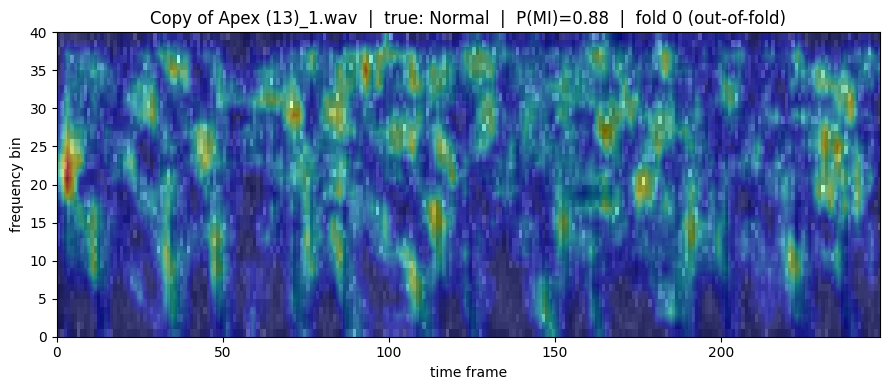

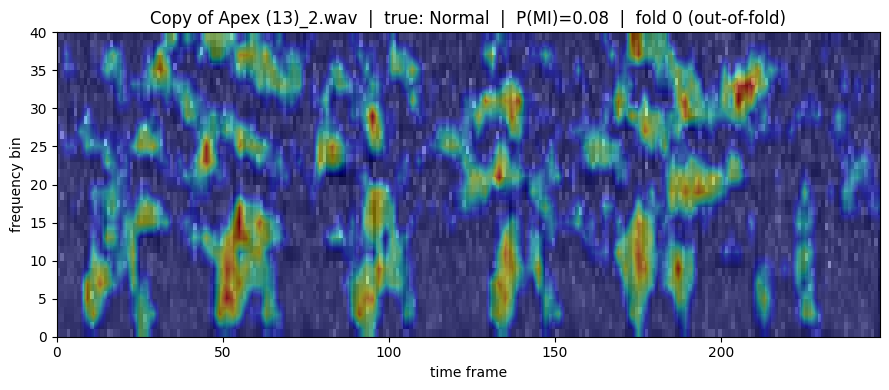

In [ ]:
def plot_oof_gradcam(row_idx):
    row = oof_df.iloc[row_idx]
    cam = cams_array[row_idx]
    signal = pad_or_trim(load_and_resample(row["filepath"], config.SAMPLE_RATE),
                         config.SAMPLE_RATE, config.CLIP_SECONDS)
    feat = calculate_features(signal)

    fig, ax = plt.subplots(figsize=(9, 4))
    ax.imshow(feat, aspect="auto", origin="lower", cmap="gray_r",
              extent=[0, feat.shape[1], 0, feat.shape[0]])
    ax.imshow(cam, aspect="auto", origin="lower", cmap="jet", alpha=0.45,
              extent=[0, feat.shape[1], 0, feat.shape[0]], interpolation="bilinear")
    ax.set_title(f"{pathlib.Path(row['filepath']).name}  |  true: {row['class_name']}  |  "
                 f"P(MI)={row['predicted_prob_mi']:.2f}  |  fold {row['fold_index']} (out-of-fold)")
    ax.set_xlabel("time frame"); ax.set_ylabel("frequency bin")
    plt.tight_layout(); plt.show()

for cls in config.CLASSES:
    idxs = oof_df.index[oof_df["class_name"] == cls].tolist()
    for i in idxs[:2]:
        plot_oof_gradcam(i)

## 5. Save this stage's outputs

In [ ]:
fold_assignments_df = pd.DataFrame(fold_assignment_rows)
fold_assignments_df.to_csv(STAGE_DIR / "fold_assignments.csv", index=False)
oof_df.to_csv(STAGE_DIR / "out_of_fold_predictions.csv", index=False)
np.savez_compressed(STAGE_DIR / "gradcam_heatmaps.npz", cams=cams_array)

config_used = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "n_folds": config.N_FOLDS,
    "inner_val_fraction": config.INNER_VAL_FRACTION,
    "batch_size": config.BATCH_SIZE,
    "epochs": config.EPOCHS,
    "learning_rate": config.LEARNING_RATE,
    "weight_decay": config.WEIGHT_DECAY,
    "label_smoothing": config.LABEL_SMOOTHING,
    "early_stopping_patience": config.EARLY_STOPPING_PATIENCE,
    "gradcam_target_class": config.GRADCAM_TARGET_CLASS,
    "n_development_recordings": int(len(dev_metadata)),
    "n_out_of_fold_explanations": int(len(oof_df)),
    "heatmap_shape_per_recording": list(cams_array.shape[1:]),
    "classifier_performance_out_of_fold": classifier_performance,
}
with open(STAGE_DIR / "config_used.json", "w") as f:
    json.dump(config_used, f, indent=2, default=str)

print("Saved:")
print(f"  {STAGE_DIR / 'fold_assignments.csv'}  ({len(fold_assignments_df)} patients)")
print(f"  {STAGE_DIR / 'out_of_fold_predictions.csv'}  ({len(oof_df)} recordings)")
print(f"  {STAGE_DIR / 'gradcam_heatmaps.npz'}  (array shape {cams_array.shape})")
print(f"  {MODELS_DIR}/fold_0.pt ... fold_{config.N_FOLDS - 1}.pt")
print(f"  {STAGE_DIR / 'config_used.json'}")

Saved:
  /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/03_train_explain/fold_assignments.csv  (112 patients)
  /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/03_train_explain/out_of_fold_predictions.csv  (2688 recordings)
  /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/03_train_explain/gradcam_heatmaps.npz  (array shape (2688, 20, 124))
  /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/03_train_explain/models/fold_0.pt ... fold_4.pt
  /content/drive/MyDrive/Research 2026/mi_marker_pipeline/artifacts/03_train_explain/config_used.json


## Next: Stage 4

Stage 4 reads this stage's `gradcam_heatmaps.npz` + `out_of_fold_predictions.csv` together
with Stage 2's `phase_boundaries.csv`, bins each heatmap into (phase × frequency-band × site)
cells, and tests MI vs Normal statistically across the development set — with fold-stability
and occlusion-based causal checks using the `N_FOLDS` model checkpoints saved here.